# Transfer learning and pretrained vision models
Two parts, both built on pretrained TensorFlow Hub models:

1. **Transfer learning**: reuse an ImageNet-trained EfficientNetV2 as a feature extractor, train a new classifier head on a *different* dataset (MNIST digits), then fine-tune the whole network with data augmentation.
2. **One image, three tasks**: run pretrained models for classification, object detection and segmentation on a single photo.

In [1]:
!pip install -q datasets tf_keras tensorflow_hub

> **Speed tip:** use a GPU runtime (Colab: *Runtime > Change runtime type > T4 GPU*). Training the network on a CPU is many times slower.

In [2]:
import json, math
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
import tf_keras                      # Keras 2 API, needed by hub.KerasLayer
import matplotlib.pyplot as plt
import requests
from io import BytesIO
from PIL import Image, ImageDraw
from datasets import load_dataset

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


---
# Part 1. Transfer learning on MNIST (handwritten digits)
### Step 1. Load and prepare the data
MNIST is 28x28 grayscale digits 0-9. We use a 6,000 image train subset and a 1,000 image test subset so training stays fast, and copy the grayscale channel 3 times because the pretrained network expects RGB.

README.md:   0%|          | 0.00/6.97k [00:00<?, ?B/s]

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

(6000, 28, 28, 3) (1000, 28, 28, 3)


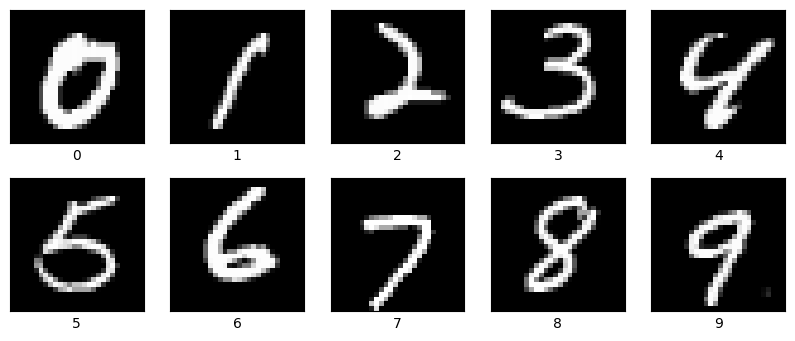

In [3]:
CLASSES = [str(i) for i in range(10)]

ds = load_dataset("ylecun/mnist")

def to_arrays(split, n):
    split = split.shuffle(seed=0).select(range(n))
    x = np.stack([np.array(im) for im in split["image"]]).astype("float32") / 255.0
    x = np.repeat(x[..., None], 3, axis=-1)           # (n, 28, 28) -> (n, 28, 28, 3)
    return x, np.array(split["label"])

train_images, train_labels = to_arrays(ds["train"], 6000)
test_images, test_labels = to_arrays(ds["test"], 1000)
print(train_images.shape, test_images.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1); plt.xticks([]); plt.yticks([])
    plt.imshow(train_images[np.where(train_labels == i)[0][0]])
    plt.xlabel(CLASSES[i])
plt.show()

### Step 2. Build the model
Pretrained EfficientNetV2 (frozen) turns each image into a feature vector; a single new `Dense` layer maps it to our 10 classes. Images are resized from 28x28 to 128x128 (smaller than the 240x240 it was trained on, but much faster).

In [4]:
IMAGE_SHAPE = (128, 128)   # the net was trained at 240, but it accepts smaller images and runs ~3.5x faster
FEATURE_URL = "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b1/feature_vector/2"

# trainable=True here only *allows* fine-tuning later; we freeze the layer for now
feature_extractor = hub.KerasLayer(FEATURE_URL, input_shape=IMAGE_SHAPE + (3,), trainable=True)
feature_extractor.trainable = False

model = tf_keras.Sequential([
    tf_keras.layers.Resizing(*IMAGE_SHAPE),
    feature_extractor,
    tf_keras.layers.Dense(len(CLASSES)),
])
model.compile(optimizer=tf_keras.optimizers.Adam(1e-3),
              loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.build((None, 28, 28, 3))
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 128, 128, 3)       0         
                                                                 
 keras_layer (KerasLayer)    (None, 1280)              6931124   
                                                                 
 dense (Dense)               (None, 10)                12810     
                                                                 
Total params: 6943934 (26.49 MB)
Trainable params: 12810 (50.04 KB)
Non-trainable params: 6931124 (26.44 MB)
_________________________________________________________________


### Step 3. Train only the new head
Only the `Dense` layer's weights are updated, since the feature extractor is frozen.

In [5]:
model.fit(train_images, train_labels, epochs=3, batch_size=64,
          validation_data=(test_images, test_labels))
_, acc_frozen = model.evaluate(test_images, test_labels)
print("Test accuracy (frozen base):", acc_frozen)

Epoch 1/3
94/94 [==============================] - 66s 656ms/step - loss: 0.9158 - accuracy: 0.7212 - val_loss: 0.5088 - val_accuracy: 0.8510
Epoch 2/3
94/94 [==============================] - 60s 644ms/step - loss: 0.4111 - accuracy: 0.8912 - val_loss: 0.3544 - val_accuracy: 0.8960
Epoch 3/3
32/32 [==============================] - 9s 275ms/step - loss: 0.2978 - accuracy: 0.9140
Test accuracy (frozen base): 0.9139999747276306


### Step 4. Look at predictions
Green = correct, red = wrong (true / predicted).

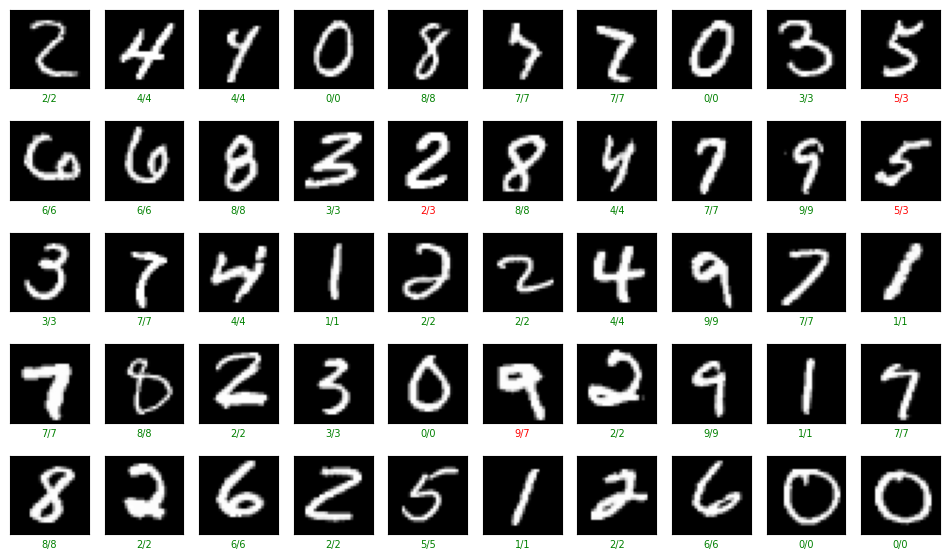

In [6]:
def show_predictions(n=50):
    pred = np.argmax(model.predict(test_images[:n], verbose=0), axis=1)
    plt.figure(figsize=(12, 7))
    for i in range(n):
        plt.subplot(5, 10, i + 1); plt.xticks([]); plt.yticks([]); plt.imshow(test_images[i])
        ok = pred[i] == test_labels[i]
        plt.xlabel(f"{CLASSES[test_labels[i]]}/{CLASSES[pred[i]]}", color='green' if ok else 'red', fontsize=7)
    plt.show()

show_predictions()

### Step 5. Fine-tune with data augmentation
Now we unfreeze the whole network, drop the learning rate 100x (so we don't destroy the pretrained weights) and train on randomly flipped / rotated / shifted images, which acts as a regulariser.

In [7]:
augment = tf_keras.Sequential([
    tf_keras.layers.RandomFlip('horizontal'),
    tf_keras.layers.RandomRotation(0.1),
    tf_keras.layers.RandomTranslation(0.1, 0.1),
])

train_ds = (tf.data.Dataset.from_tensor_slices((train_images, train_labels))
            .shuffle(6000).batch(64)
            .map(lambda x, y: (augment(x, training=True), y))
            .prefetch(tf.data.AUTOTUNE))

feature_extractor.trainable = True
model.compile(optimizer=tf_keras.optimizers.Adam(1e-5),           # recompile so the change takes effect
              loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(train_ds, epochs=2, validation_data=(test_images, test_labels))
_, acc_ft = model.evaluate(test_images, test_labels)
print(f"Frozen base: {acc_frozen:.3f}  ->  fine-tuned: {acc_ft:.3f}")

Epoch 1/2
94/94 [==============================] - 266s 3s/step - loss: 2.9032 - accuracy: 0.2365 - val_loss: 1.9552 - val_accuracy: 0.4340
Epoch 2/2
32/32 [==============================] - 9s 294ms/step - loss: 1.5649 - accuracy: 0.5070
Frozen base: 0.914  ->  fine-tuned: 0.507


---
# Part 2. One image, three tasks
Pretrained models only, no training. Change `IMG_URL` to try another photo.
### Setup: image loading and models

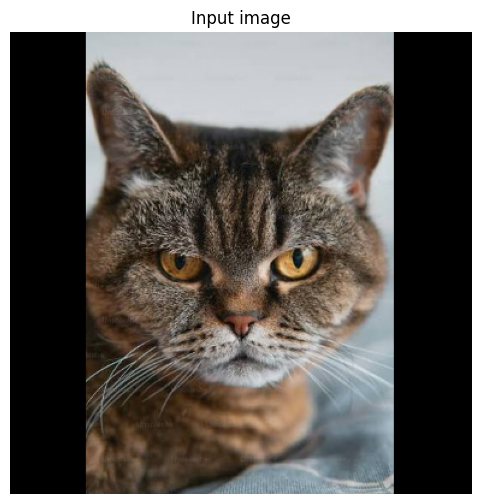

In [8]:
IMG_URL = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQBEA2rPU99lt1Fg43YFICe_HxDgk0CRI1rMnNOGChg1Y7Av--9OtIK2KrN&s=10"   # any direct image link works

def load_image(url, size):
    """Returns (resized float image [1,size,size,3], original float image [1,H,W,3]), values in [0,1]."""
    r = requests.get(url, headers={'User-agent': 'C'})
    r.raise_for_status()                       # shows the real HTTP error instead of a confusing PIL one
    img = Image.open(BytesIO(r.content)).convert("RGB")
    original = tf.convert_to_tensor(np.array(img)[None], tf.float32) / 255.0
    return tf.image.resize_with_pad(original, size, size), original

def show(image, title=''):
    plt.figure(figsize=(6, 6)); plt.imshow(image[0]); plt.axis('off'); plt.title(title); plt.show()

def top_k(image, model, labels, k=4):
    p = tf.nn.softmax(model(image)).numpy()[0]
    for rank, idx in enumerate(np.argsort(-p)[:k], 1):
        print(f"{rank}) {labels[idx]:<30} p = {p[idx]:.4f}")

INPUT_SIZE = 384
image, original_image = load_image(IMG_URL, INPUT_SIZE)
show(image, 'Input image')

### Classification with two models
Model 1 is trained on ImageNet-21k (21k classes). Model 2 is the same architecture fine-tuned on ImageNet-1k (1k classes), so its labels are fewer and coarser.

In [9]:
clf21k = hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_s/classification/2")
clf1k  = hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_s/classification/2")

labels21k = np.array(open(tf.keras.utils.get_file('in21k.txt',
    'https://huggingface.co/spaces/TexR6/AttentionMaps/resolve/main/labels/imagenet21k_wordnet_lemmas.txt')).read().splitlines())
labels1k = np.array(open(tf.keras.utils.get_file('in1k.txt',
    'https://storage.googleapis.com/download.tensorflow.org/data/ImageNetLabels.txt')).read().splitlines())[1:]

print("Model 1 (ImageNet-21k):"); top_k(image, clf21k, labels21k)
print("\nModel 2 (ImageNet-1k):"); top_k(image, clf1k, labels1k)

522999/522999 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
10484/10484 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model 1 (ImageNet-21k):
1) tom, tomcat                    p = 0.1856
2) cat, true_cat                  p = 0.1550
3) domestic_cat, house_cat, Felis_domesticus, Felis_catus p = 0.1457
4) kitty, kitty-cat, puss, pussy, pussycat p = 0.0746

Model 2 (ImageNet-1k):
1) tabby                          p = 0.4459
2) tiger cat                      p = 0.3450
3) Egyptian cat                   p = 0.1228
4) lynx                           p = 0.0073


**Crop test:** zoom into a part of the photo and see whether the predictions change. Set the crop position (% of width/height) and size (pixels).

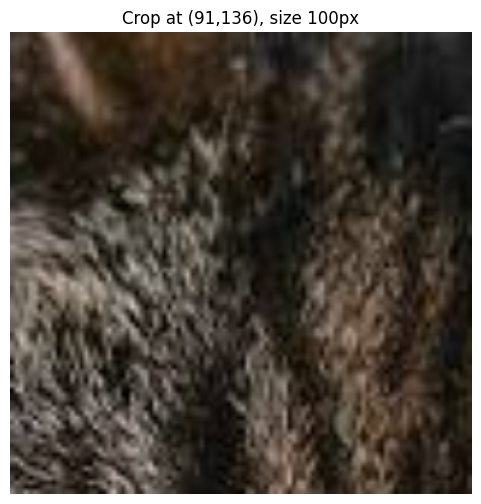

Model 1:
1) water-skiing                   p = 0.0176
2) lame                           p = 0.0086
3) surfing, surfboarding, surfriding p = 0.0086
4) aquaplane                      p = 0.0079

Model 2:
1) tick                           p = 0.1427
2) wool                           p = 0.0667
3) velvet                         p = 0.0536
4) platypus                       p = 0.0407


In [10]:
x_pct, y_pct, cut = 25, 25, 100   # the image is small, so keep the crop small

x0, y0 = int(original_image.shape[2] * x_pct / 100), int(original_image.shape[1] * y_pct / 100)
cut = min(cut, original_image.shape[1] - y0, original_image.shape[2] - x0)   # stay inside the image
crop = tf.image.resize(original_image[:, y0:y0 + cut, x0:x0 + cut, :], [INPUT_SIZE, INPUT_SIZE])
show(crop, f'Crop at ({x0},{y0}), size {cut}px')

print("Model 1:"); top_k(crop, clf21k, labels21k)
print("\nModel 2:"); top_k(crop, clf1k, labels1k)

### Object detection
An SSD-MobileNet detector (Open Images, 600 classes) returns bounding boxes with a class and a confidence score for each object.

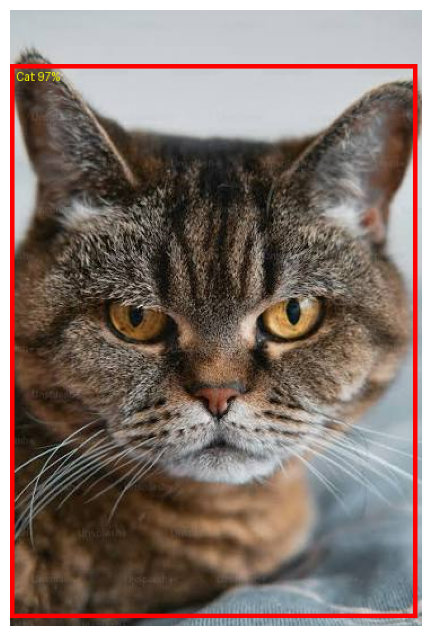

In [11]:
detector = hub.load("https://tfhub.dev/google/openimages_v4/ssd/mobilenet_v2/1").signatures['default']

def detect(img, min_score=0.3, max_boxes=10):
    out = {k: v.numpy() for k, v in detector(img).items()}
    pil = Image.fromarray((img[0].numpy() * 255).astype("uint8"))
    draw, (w, h) = ImageDraw.Draw(pil), pil.size
    for box, cls, score in list(zip(out["detection_boxes"], out["detection_class_entities"], out["detection_scores"]))[:max_boxes]:
        if score < min_score: continue
        ymin, xmin, ymax, xmax = box
        draw.rectangle([xmin * w, ymin * h, xmax * w, ymax * h], outline="red", width=4)
        draw.text((xmin * w + 5, ymin * h + 5), f"{cls.decode()}: {int(score * 100)}%", fill="yellow")
    plt.figure(figsize=(10, 8)); plt.imshow(pil); plt.axis('off'); plt.show()

detect(original_image)

### Semantic segmentation
HRNet (ADE20K, 150 classes) labels **every pixel** with a class. It outputs one mask per class; below we overlay the 4 classes that cover the most pixels.

2814/2814 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


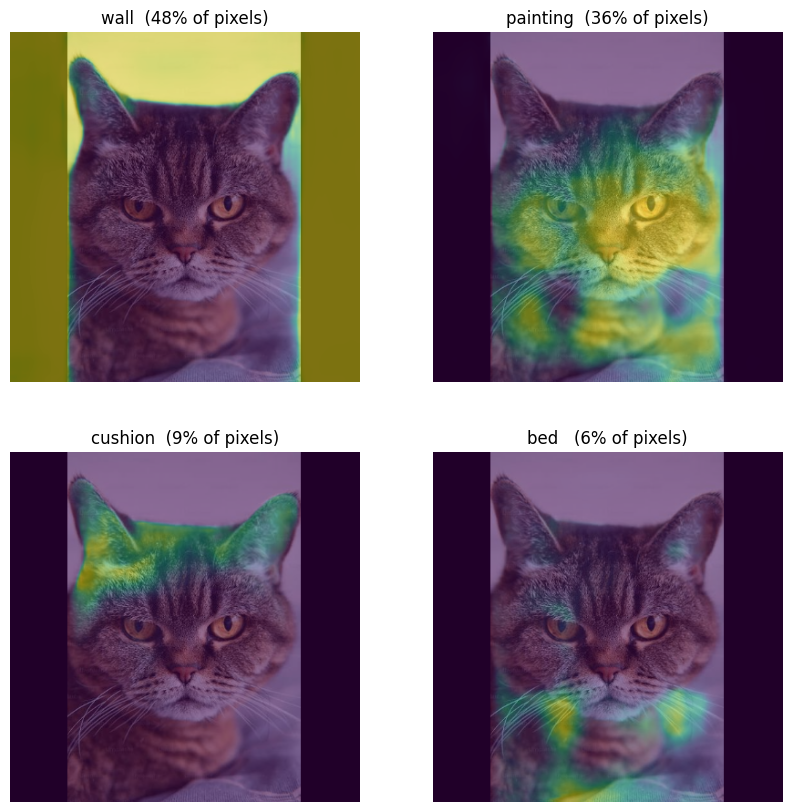

In [12]:
seg_model = hub.load('https://tfhub.dev/google/HRNet/ade20k-hrnetv2-w48/1')
id2label = json.load(open(tf.keras.utils.get_file('ade20k.json',
    'https://huggingface.co/datasets/huggingface/label-files/raw/main/ade20k-id2label.json')))
seg_labels = ['background'] + list(id2label.values())

pred = np.array(seg_model.predict(image)[0])               # (h, w, n_classes), as a numpy array
area = np.bincount(pred.argmax(-1).ravel(), minlength=pred.shape[-1])
top = np.argsort(-area)[:4]

plt.figure(figsize=(10, 10))
for n, c in enumerate(top):
    name = seg_labels[c] if c < len(seg_labels) else f"class {c}"
    plt.subplot(2, 2, n + 1); plt.axis('off')
    plt.imshow(image[0]); plt.imshow(pred[:, :, c], alpha=0.5)
    plt.title(f"{name}  ({area[c] / area.sum():.0%} of pixels)")
plt.show()

---
## Summary
* **Transfer learning:** a network pretrained on ImageNet photos classifies handwritten digits after training only a small head; fine-tuning all layers at a low learning rate with augmentation usually improves it further.
* **Pretrained models:** the same kind of backbone supports classification (one label per image), detection (boxes + labels) and segmentation (a label per pixel) without any training of our own.